## Test training


In [2]:
%load_ext autoreload
%autoreload 1

import os
os.environ["QUANTDATA_ROOT"] = "/mnt/c/Users/Public/quantdata"

from cdxcore.verbose import Context
verbose = Context("all")
with verbose.write_t("Importing torch...", end='') as tme:   
    import torch
    verbose.write(f"done; this took {tme}.", head=False)

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.torch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler

from quantdata.dysanos.simple.sampler import SimpleSampler, SimpleConfig, SamplingConfig, ExpiryFilter, RawDayFilter, SampleDaysConfig, DateRange, PoolConfig
from cdxcore.verbose import Context
from datetime import date

def test():
    simple_config = SimpleConfig(
            tickers = ['SPX','NDX','RUT'],
            date_range = DateRange(start=date(2015, 1, 1), end=date(2025, 7, 1)),
            raw_day_filter = RawDayFilter(),
            expiry_filter = ExpiryFilter(),
            sample_days_config = SampleDaysConfig(),
            sampling_config = SamplingConfig(num_samples=20)
    )
    pool_config = PoolConfig(num_workers=4, threading=False) # no parallel processing for testing
    verbose = Context.all
    refresh_cache = False

    sampler = SimpleSampler(simple_config=simple_config, pool_config=pool_config, refresh_cache=refresh_cache, verbose=verbose)
    return sampler

sampler = test()
print("/done")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
00: Importing torch...done; this took 0.0176ms.
00: Generating samples for 3 tickers NDX, RUT and SPX with from 2015-01-01 to 2025-07-01... 01:   Collecting enriched data for ticker NDX for 2619 business days from 2015-01-02 to 2025-07-01 excluding half days.
03:       Sample Days Config: nopt=1000,bdte=756,nms=4.0,lvolu=1.0,loi=1.0,rmam=False,vegaSqrtVar=0.001
03:       Raw Day Filter: bid=0.011
03:       Expiry filter: eth=10,bth=4
03:       Pool config: workers 4p
01:   Checking which enriched daily data files for ticker NDX and the 2619 business days from 2015-01-02 to 2025-07-01 excluding half days exist in the cache... all daily data files exist and have been loaded. This took 19s.
02:     The following 2 business days where removed because they had no data after filtering: 2018-12-04 and 2025-01-08.
01:   Generating sample for 2617 business days and at most 367 options per day for ticker NDX.

## Training a simple MLP

/model created.
01:   Launching AEC training for 1000 epochs over 1233 training and 309 validation samples, using a mini bastch size of 16 for 10 batches per epoch, and a batch size of 64 for valuation. The model has 31809 parameters.
01:   Training epoch 1/1000 error avg trn 0.06419; val 0.008199/0.009856 [2s 3s 0.8s]. LR: 1.00e-03, GN 0.01354, excess: 0.009937/0.01067. ETA: 2:13:28.


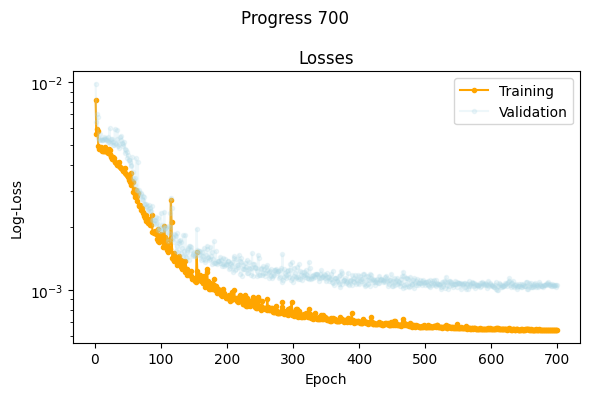

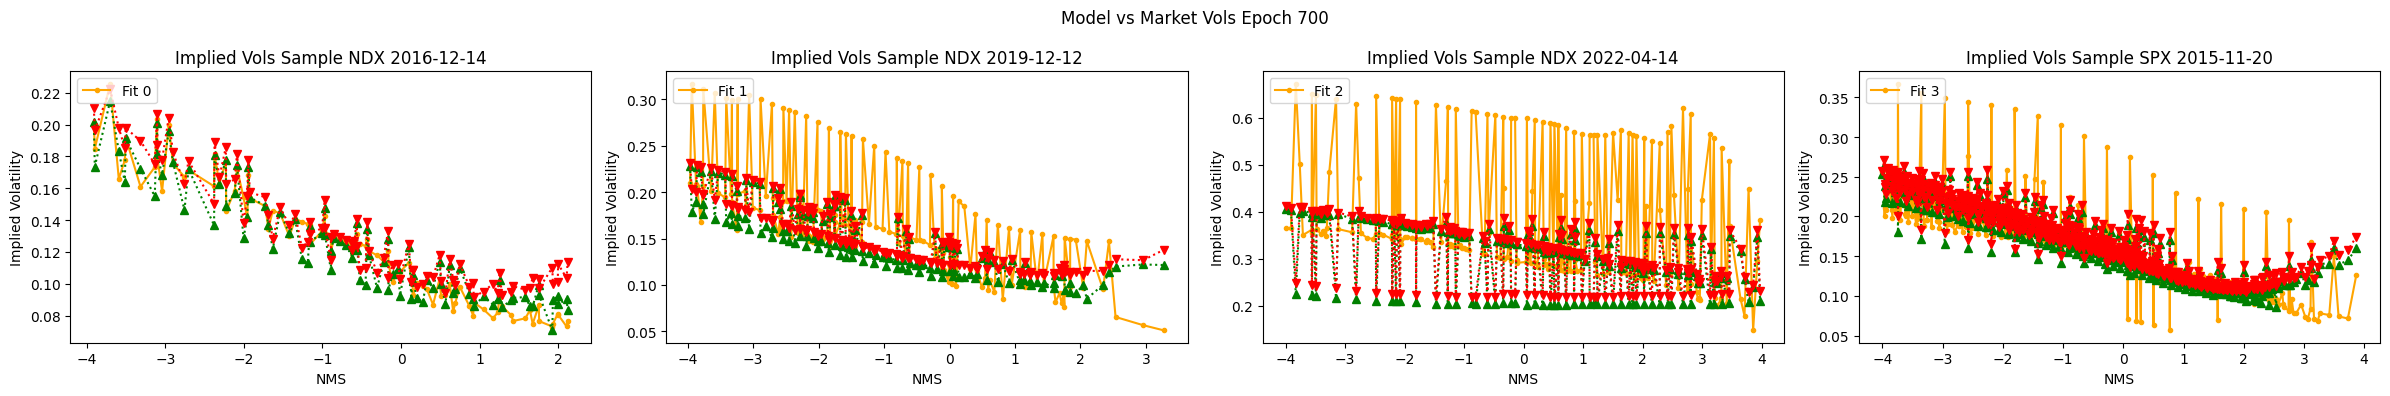

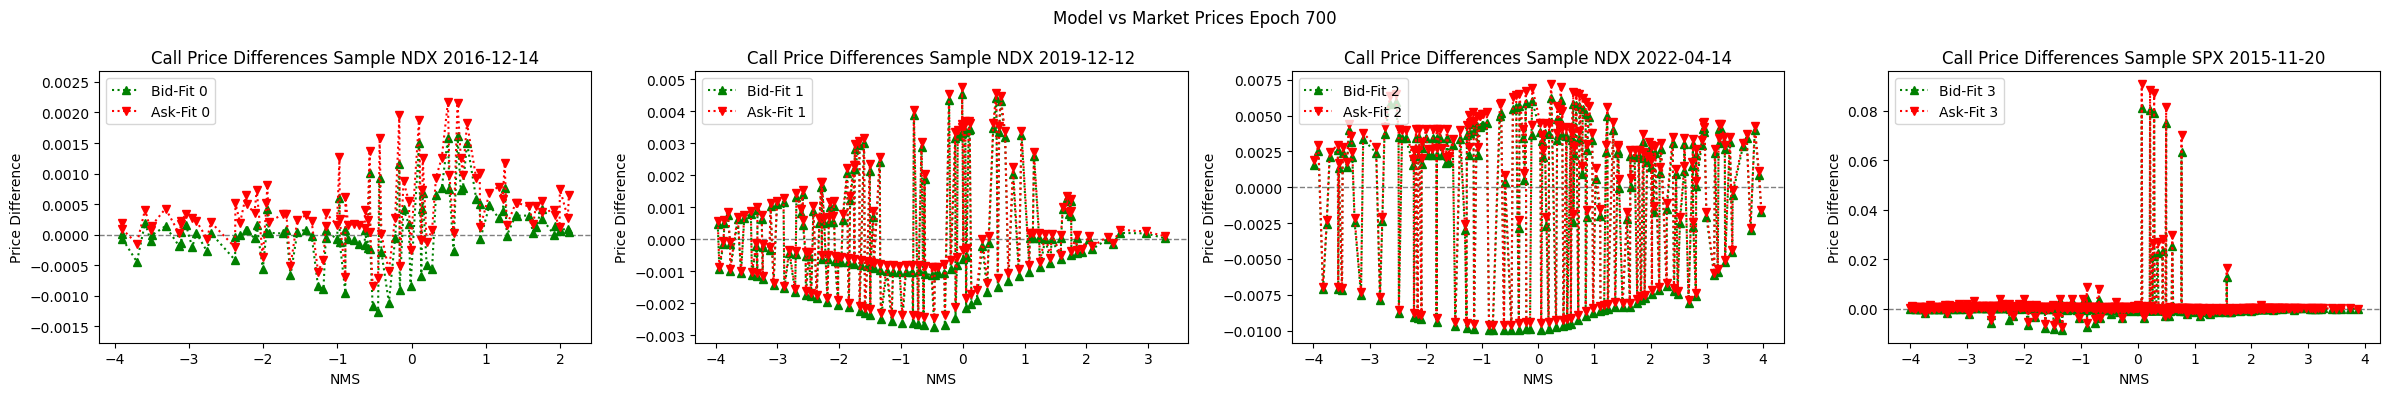

01:   Training epoch 2/1000 error avg trn 0.0057; val 0.005642/0.006455 [2s 3s 0.81s]. LR: 1.00e-03, GN 0.0006391, excess: 0.01064/0.01149. ETA: 4:21:28.
01:   Training epoch 3/1000 error avg trn 0.005439; val 0.005942/0.007049 [2s 3s 0.81s]. LR: 1.00e-03, GN 0.0004637, excess: 0.01106/0.01218. ETA: 6:25:11.
01:   Training epoch 4/1000 error avg trn 0.00633; val 0.005803/0.006771 [2s 3s 0.8s]. LR: 1.00e-03, GN 0.0005281, excess: 0.01087/0.01186. ETA: 8:25:36.
01:   Training epoch 5/1000 error avg trn 0.005554; val 0.004948/0.005373 [2s 3s 0.81s]. LR: 1.00e-03, GN 0.001596, excess: 0.009454/0.009816. ETA: 10:25:37.
01:   Training epoch 6/1000 error avg trn 0.004391; val 0.004774/0.005273 [2s 3s 0.8s]. LR: 1.00e-03, GN 0.0008607, excess: 0.008863/0.009154. ETA: 12:25:37.
01:   Training epoch 7/1000 error avg trn 0.004928; val 0.004756/0.005278 [2s 3s 0.8s]. LR: 1.00e-03, GN 0.001586, excess: 0.008807/0.009094. ETA: 14:26:15.
01:   Training epoch 8/1000 error avg trn 0.0054; val 0.004841/

KeyboardInterrupt: 

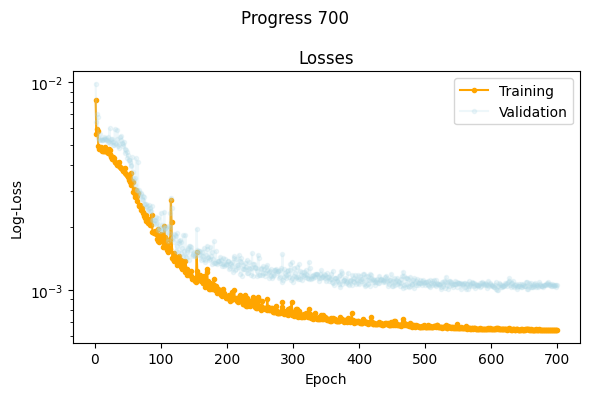

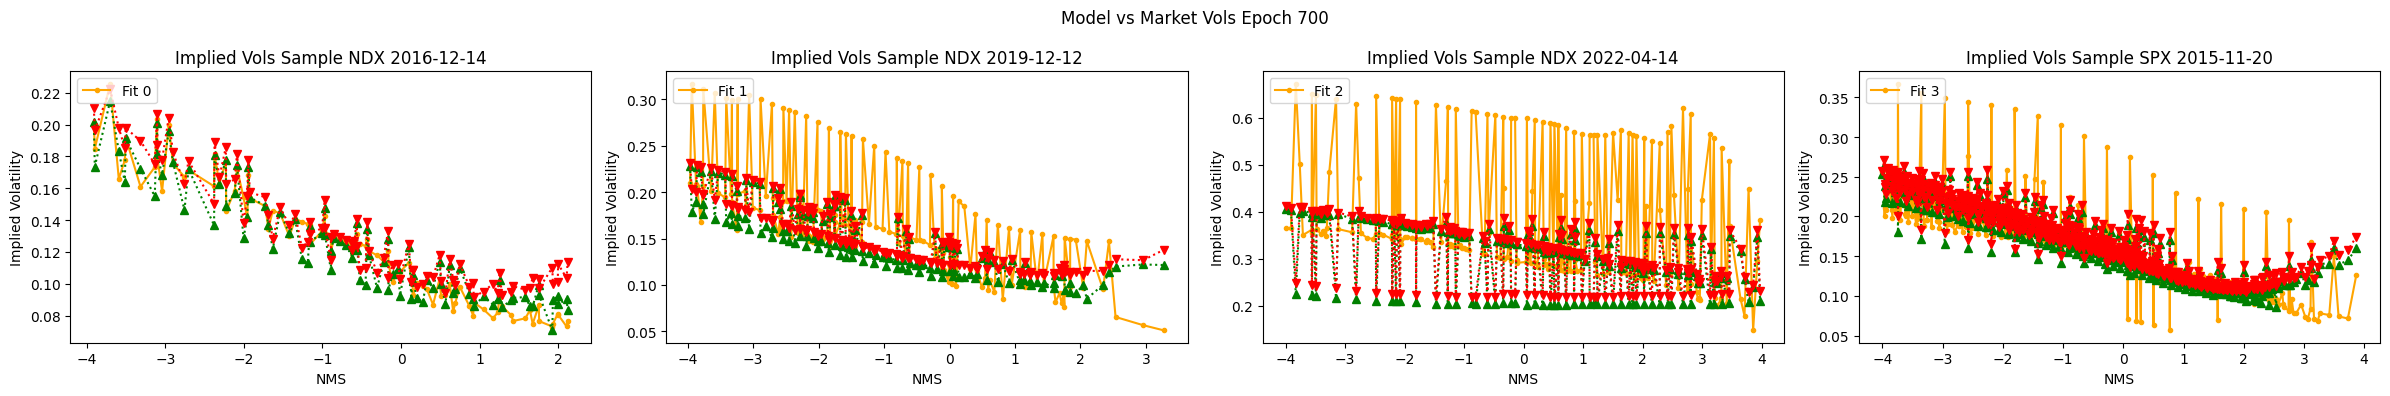

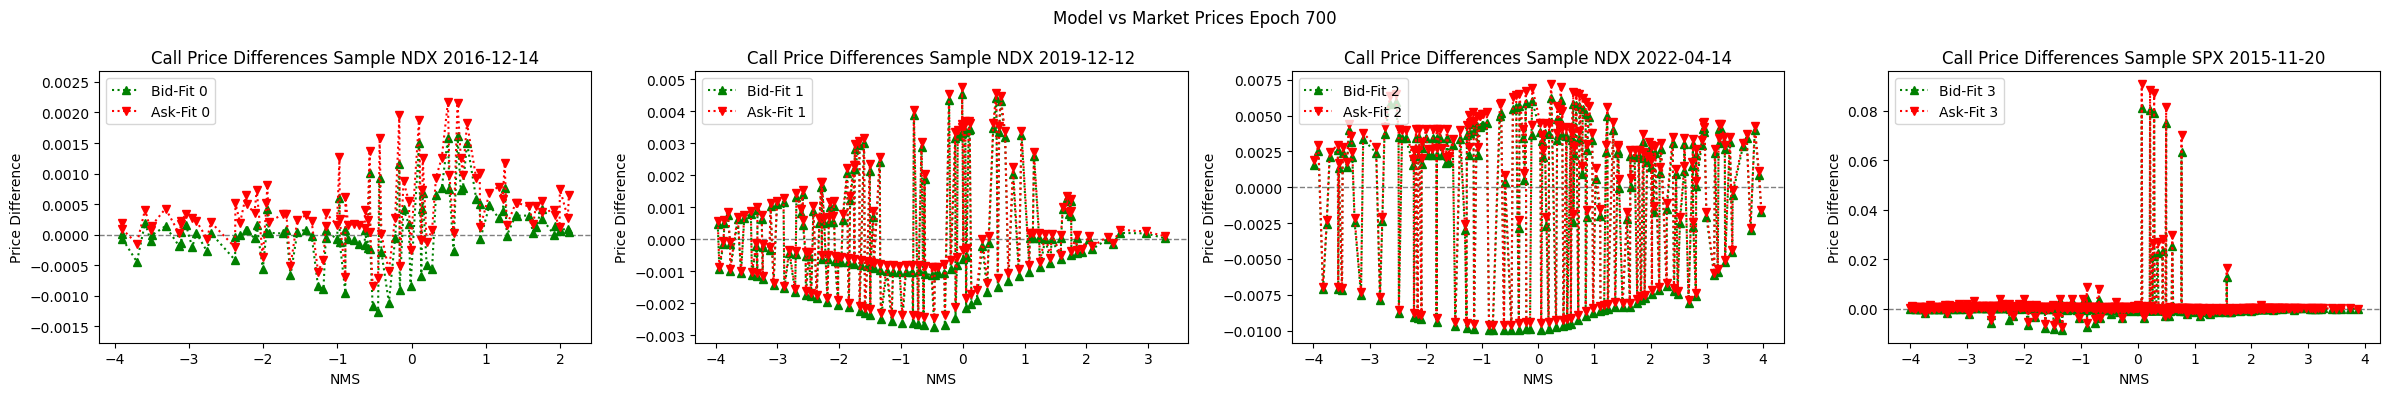

In [3]:
# reloader

%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.sampler
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer

from quantdata.dysanos.simple.model import AEC, BaseEnvironment, FeedForward
from quantdata.dysanos.simple.trainer import train, TrainConfig

env   = BaseEnvironment(device="cuda", debug=False)

aec_config = AEC.Config(
    num_state = 32,
    num_compress = 128   ,
    encode_what = "sqrtVar",
    mid_fit_weight = 0.1,
    encoder_set_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    encoder_fix_config = FeedForward.Config(
        num_depth = 2,
        num_width = 64,
        activation = 'ReLU',
    ),
    decoder_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    vizualizer_config = AEC.VisualizerConfig()
)

model = AEC(env=env, 
            shapes=sampler.shapes(), 
            stats=sampler.stats,
            num_steps=sampler.num_steps,
            max_options=sampler.max_options,
            config=aec_config )

print("/model created.")

train( env, epochs=1000, model=model, sampler=sampler, config=TrainConfig(), verbose=verbose(1) )
